In [5]:
import numpy as np

x_difference = -0.11789663
y_difference = 0.00644788

distance = np.linalg.norm([x_difference, y_difference])
print(distance)

0.11807281872578167


In [10]:
import gymnasium as gym 
import numpy as np

env  = gym.make("Reacher-v5", render_mode="human")

import numpy as np

observation, info = env.reset(seed=42)
action = np.array([0.05, -0.10])

start_distance = np.linalg.norm(observation[8:10])
print(f"Start: distance = {start_distance:.6f}")

step_number = 0
terminated = False
truncated = False

while not (terminated or truncated):
    observation, reward, terminated, truncated, info = env.step(action)
    step_number += 1

    distance = np.linalg.norm(observation[8:10])
    print(f"Step {step_number}: distanc{reward:.6f}")

env.close()

Start: distance = 0.148185
Step 1: distanc-0.160710
Step 2: distanc-0.160757
Step 3: distanc-0.160815
Step 4: distanc-0.160868
Step 5: distanc-0.160896
Step 6: distanc-0.160871
Step 7: distanc-0.160764
Step 8: distanc-0.160540
Step 9: distanc-0.160162
Step 10: distanc-0.159593
Step 11: distanc-0.158795
Step 12: distanc-0.157732
Step 13: distanc-0.156373
Step 14: distanc-0.154692
Step 15: distanc-0.152677
Step 16: distanc-0.150330
Step 17: distanc-0.147674
Step 18: distanc-0.144760
Step 19: distanc-0.141677
Step 20: distanc-0.138559
Step 21: distanc-0.135591
Step 22: distanc-0.133025
Step 23: distanc-0.131170
Step 24: distanc-0.130385
Step 25: distanc-0.131044
Step 26: distanc-0.133491
Step 27: distanc-0.137982
Step 28: distanc-0.144640
Step 29: distanc-0.153441
Step 30: distanc-0.164233
Step 31: distanc-0.169320
Step 32: distanc-0.166463
Step 33: distanc-0.162947
Step 34: distanc-0.160009
Step 35: distanc-0.157722
Step 36: distanc-0.155899
Step 37: distanc-0.154366
Step 38: distanc-0.1

In [12]:
import gymnasium as gym
import numpy as np

env = gym.make("Reacher-v5", render_mode="human")
observation, info = env.reset(seed=42)

action = np.array([0.05, -0.10], dtype=np.float32)
print(f"Start distance: {np.linalg.norm(observation[8:10]):.6f}")

step_number = 0
terminated = False
truncated = False

while not (terminated or truncated):
    observation, reward, terminated, truncated, info = env.step(action)
    step_number += 1
    distance = np.linalg.norm(observation[8:10])
    print(f"Step {step_number}: distance = {distance:.6f}, reward = {reward:.6f}")

env.close()    

Start distance: 0.148185
Step 1: distance = 0.148210, reward = -0.160710
Step 2: distance = 0.148257, reward = -0.160757
Step 3: distance = 0.148315, reward = -0.160815
Step 4: distance = 0.148368, reward = -0.160868
Step 5: distance = 0.148396, reward = -0.160896
Step 6: distance = 0.148371, reward = -0.160871
Step 7: distance = 0.148264, reward = -0.160764
Step 8: distance = 0.148040, reward = -0.160540
Step 9: distance = 0.147662, reward = -0.160162
Step 10: distance = 0.147093, reward = -0.159593
Step 11: distance = 0.146295, reward = -0.158795
Step 12: distance = 0.145232, reward = -0.157732
Step 13: distance = 0.143873, reward = -0.156373
Step 14: distance = 0.142192, reward = -0.154692
Step 15: distance = 0.140177, reward = -0.152677
Step 16: distance = 0.137830, reward = -0.150330
Step 17: distance = 0.135174, reward = -0.147674
Step 18: distance = 0.132260, reward = -0.144760
Step 19: distance = 0.129177, reward = -0.141677
Step 20: distance = 0.126059, reward = -0.138559
Step

Matplotlib is building the font cache; this may take a moment.


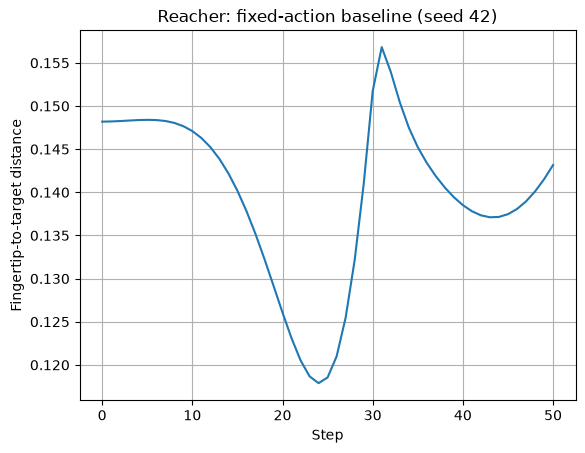

Closest distance: 0.117885 at step 24


In [14]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
observation, info = env.reset(seed=42)
action = np.array([0.05, -0.10], dtype=np.float32)

distances = [np.linalg.norm(observation[8:10])]

terminated = False
truncated = False

while not (terminated or truncated):
    observation, reward, terminated, truncated, info = env.step(action)
    distances.append(np.linalg.norm(observation[8:10]))

env.close()

steps = range(len(distances))  # 0 is before the first action
plt.plot(steps, distances)
plt.xlabel("Step")
plt.ylabel("Fingertip-to-target distance")
plt.title("Reacher: fixed-action baseline (seed 42)")
plt.grid(True)
plt.show()

closest_step = int(np.argmin(distances))
print(f"Closest distance: {distances[closest_step]:.6f} at step {closest_step}")

- It starts around 0.148.
- It gets closest at about step 24–25, around 0.118.
- Then it moves sharply away, reaching about 0.157 near step 31.
- It comes closer again around step 43, but finishes around 0.143.

In [18]:
import gymnasium as gym
import numpy as np

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)

print("Seed | Start distance | Closest distance | Final distance | Total reward")
print("-" * 75)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    start_distance = np.linalg.norm(observation[8:10])
    closest_distance = start_distance
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)

        distance = np.linalg.norm(observation[8:10])
        closest_distance = min(closest_distance, distance)
        total_reward += reward

    final_distance = distance
    print(
        f"{seed:4d} | {start_distance:14.6f} | {closest_distance:16.6f} "
        f"| {final_distance:14.6f} | {total_reward:12.6f}"
    )

env.close()

Seed | Start distance | Closest distance | Final distance | Total reward
---------------------------------------------------------------------------
  42 |       0.148185 |         0.117885 |       0.143159 |    -7.600587
  43 |       0.204758 |         0.100117 |       0.132823 |    -8.017413
  44 |       0.381065 |         0.184949 |       0.184949 |   -14.779082
  45 |       0.232501 |         0.094004 |       0.094014 |    -8.725283
  46 |       0.188319 |         0.103920 |       0.106769 |    -7.687580
  47 |       0.352997 |         0.172633 |       0.172633 |   -13.909960
  48 |       0.209893 |         0.139695 |       0.141191 |    -9.292453
  49 |       0.255981 |         0.145768 |       0.173213 |   -10.512340
  50 |       0.316714 |         0.111821 |       0.111821 |   -11.441349
  51 |       0.159109 |         0.112552 |       0.175248 |    -8.011542


Seed | Start distance | Closest distance | Final distance | Total reward
---------------------------------------------------------------------------
  42 |       0.148185 |         0.117885 |       0.143159 |    -7.600587
  43 |       0.204758 |         0.100117 |       0.132823 |    -8.017413
  44 |       0.381065 |         0.184949 |       0.184949 |   -14.779082
  45 |       0.232501 |         0.094004 |       0.094014 |    -8.725283
  46 |       0.188319 |         0.103920 |       0.106769 |    -7.687580
  47 |       0.352997 |         0.172633 |       0.172633 |   -13.909960
  48 |       0.209893 |         0.139695 |       0.141191 |    -9.292453
  49 |       0.255981 |         0.145768 |       0.173213 |   -10.512340
  50 |       0.316714 |         0.111821 |       0.111821 |   -11.441349
  51 |       0.159109 |         0.112552 |       0.175248 |    -8.011542


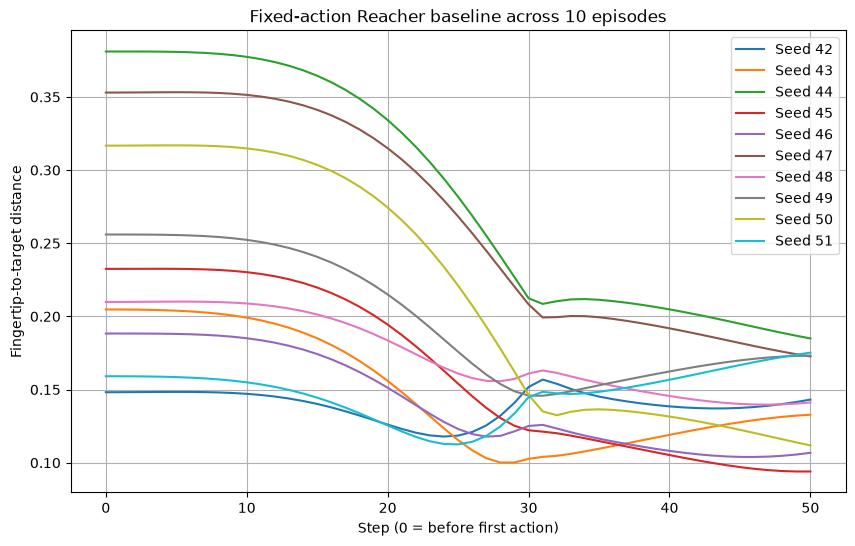

In [21]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward")
print("-" * 75)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward

    print(
        f"{seed:4d} | {distances[0]:14.6f} | {min(distances):16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f}"
    )

    plt.plot(range(len(distances)), distances, label=f"Seed {seed}")

env.close()

plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Fixed-action Reacher baseline across 10 episodes")
plt.grid(True)
plt.legend()
plt.show()

 all 10 episodes got closer to the target at some point—each “closest distance” is smaller than its starting distance. But they did not all finish at their closest point. For example, seed 51 reached about 0.113 and then finished farther away at 0.175. Seed 44 finished at its closest recorded distance, about 0.185.

# with threshold

Seed | Start distance | Closest distance | Final distance | Total reward | Success
-------------------------------------------------------------------------------------
  42 |       0.148185 |         0.117885 |       0.143159 |    -7.600587 | False
  43 |       0.204758 |         0.100117 |       0.132823 |    -8.017413 | False
  44 |       0.381065 |         0.184949 |       0.184949 |   -14.779082 | False
  45 |       0.232501 |         0.094004 |       0.094014 |    -8.725283 | False
  46 |       0.188319 |         0.103920 |       0.106769 |    -7.687580 | False
  47 |       0.352997 |         0.172633 |       0.172633 |   -13.909960 | False
  48 |       0.209893 |         0.139695 |       0.141191 |    -9.292453 | False
  49 |       0.255981 |         0.145768 |       0.173213 |   -10.512340 | False
  50 |       0.316714 |         0.111821 |       0.111821 |   -11.441349 | False
  51 |       0.159109 |         0.112552 |       0.175248 |    -8.011542 | False


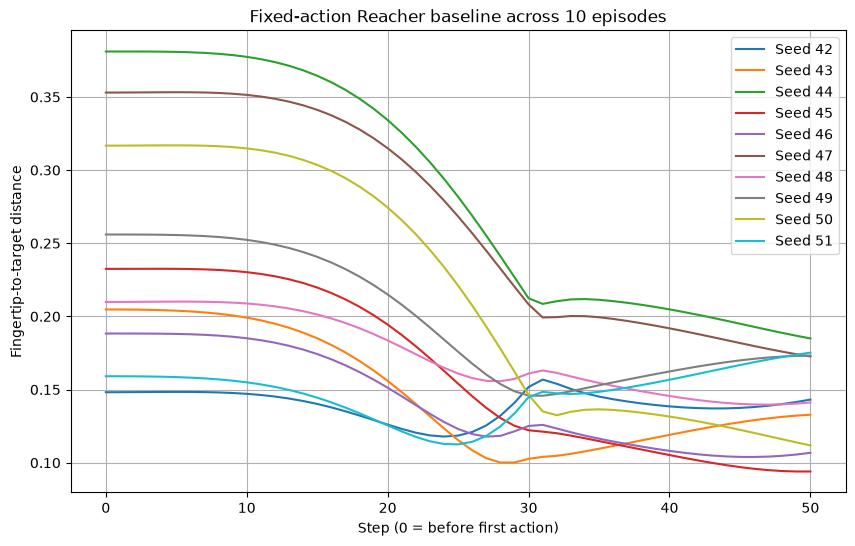

In [24]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)
success_threshold = 0.05

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward | Success")
print("-" * 85)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward

    closest_distance = min(distances)
    success = closest_distance <= success_threshold

    print(
        f"{seed:4d} | {distances[0]:14.6f} | {closest_distance:16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
    )

    plt.plot(range(len(distances)), distances, label=f"Seed {seed}")

env.close()

plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Fixed-action Reacher baseline across 10 episodes")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)
success_threshold = 0.05

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward | Success")
print("-" * 85)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward

    closest_distance = min(distances)
    success = closest_distance <= success_threshold

    print(
        f"{seed:4d} | {distances[0]:14.6f} | {closest_distance:16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
    )

    plt.plot(range(len(distances)), distances, label=f"Seed {seed}")

env.close()

plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Fixed-action Reacher baseline across 10 episodes")
plt.grid(True)
plt.legend()
plt.show()

In [29]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

def policy(observation):
    x_offset = observation[8]
    
    if x_offset < 0:
        return np.array([0.05, -0.10], dtype=np.float32)
    else:
        return np.array([-0.05, -0.10], dtype=np.float32)
    
env = gym.make("Reacher-v5", render_mode="human")
observation, info = env.reset(seed=42)

terminated = False
truncated = False
step_number = 0

while not (terminated or truncated):
    x_offset = observation[8]
    action = policy(observation)
    print(f"Step {step_number + 1}: x_offset={x_offset:.6f}, action={action}")
    observation, reward, terminated, truncated, info = env.step(action)
    step_number += 1    
env.close()

Step 1: x_offset=0.105294, action=[-0.05 -0.1 ]
Step 2: x_offset=0.105332, action=[-0.05 -0.1 ]
Step 3: x_offset=0.105415, action=[-0.05 -0.1 ]
Step 4: x_offset=0.105470, action=[-0.05 -0.1 ]
Step 5: x_offset=0.105373, action=[-0.05 -0.1 ]
Step 6: x_offset=0.104961, action=[-0.05 -0.1 ]
Step 7: x_offset=0.104033, action=[-0.05 -0.1 ]
Step 8: x_offset=0.102354, action=[-0.05 -0.1 ]
Step 9: x_offset=0.099664, action=[-0.05 -0.1 ]
Step 10: x_offset=0.095687, action=[-0.05 -0.1 ]
Step 11: x_offset=0.090142, action=[-0.05 -0.1 ]
Step 12: x_offset=0.082761, action=[-0.05 -0.1 ]
Step 13: x_offset=0.073305, action=[-0.05 -0.1 ]
Step 14: x_offset=0.061589, action=[-0.05 -0.1 ]
Step 15: x_offset=0.047504, action=[-0.05 -0.1 ]
Step 16: x_offset=0.031043, action=[-0.05 -0.1 ]
Step 17: x_offset=0.012327, action=[-0.05 -0.1 ]
Step 18: x_offset=-0.008371, action=[ 0.05 -0.1 ]
Step 19: x_offset=-0.029983, action=[ 0.05 -0.1 ]
Step 20: x_offset=-0.051273, action=[ 0.05 -0.1 ]
Step 21: x_offset=-0.07160

Seed | Start distance | Closest distance | Final distance | Total reward | Success
-------------------------------------------------------------------------------------
Start distance:   0.159109
Closest distance: 0.030199
Final distance:   0.158383
Total reward:     -7.315249
Success:          True


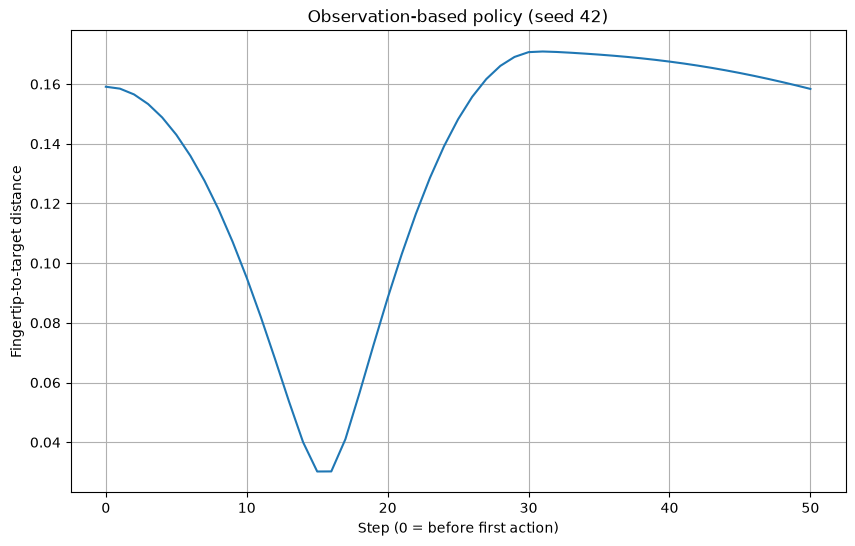

In [31]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

def policy(observation):
    x_offset = observation[8]
    
    if x_offset < 0:
        return np.array([0.05, -0.10], dtype=np.float32)
    else:
        return np.array([-0.05, -0.10], dtype=np.float32)
    
env = gym.make("Reacher-v5", render_mode="human")
success_threshold = 0.05

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward | Success")
print("-" * 85)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        x_offset = observation[8]
        action = policy(observation)
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward
env.close()

closest_distance = min(distances)
success = closest_distance <= success_threshold
print(f"Start distance:   {distances[0]:.6f}")
print(f"Closest distance: {closest_distance:.6f}")
print(f"Final distance:   {distances[-1]:.6f}")
print(f"Total reward:     {total_reward:.6f}")
print(f"Success:          {success}")

plt.plot(range(len(distances)), distances)
plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Observation-based policy (seed 42)")
plt.grid(True)
plt.show()


Start distance:   0.148185
Closest distance: 0.148185
Final distance:   0.172645
Total reward:     -10.640841
Success:          False


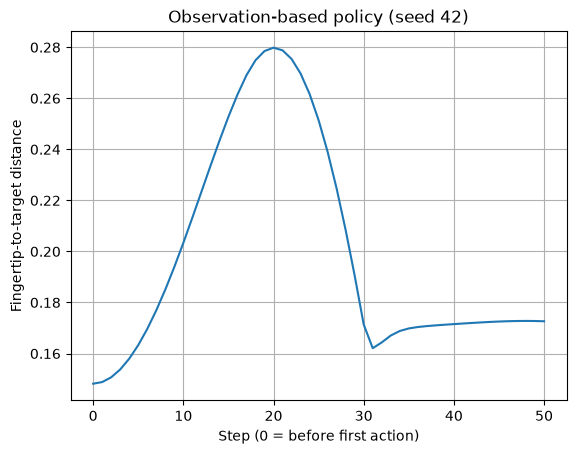

In [32]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

def policy(observation):
    x_offset = observation[8]
    
    if x_offset < 0:
        return np.array([0.05, -0.10], dtype=np.float32)
    else:
        return np.array([-0.05, -0.10], dtype=np.float32)
    
env = gym.make("Reacher-v5", render_mode="human")
observation, info = env.reset(seed=42)
distances = [np.linalg.norm(observation[8:10])]  # Step 0
total_reward = 0.0
terminated = False
truncated = False

while not (terminated or truncated):
    x_offset = observation[8]
    action = policy(observation)
    observation, reward, terminated, truncated, info = env.step(action)
    distances.append(np.linalg.norm(observation[8:10]))
    total_reward += reward
env.close()

closest_distance = min(distances)
success = closest_distance <= success_threshold
print(f"Start distance:   {distances[0]:.6f}")
print(f"Closest distance: {closest_distance:.6f}")
print(f"Final distance:   {distances[-1]:.6f}")
print(f"Total reward:     {total_reward:.6f}")
print(f"Success:          {success}")

plt.plot(range(len(distances)), distances)
plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Observation-based policy (seed 42)")
plt.grid(True)
plt.show()


Seed | Start distance | Closest distance | Final distance | Total reward | Success
-------------------------------------------------------------------------------------
  42 |       0.148185 |         0.148185 |       0.172645 |   -10.640841 | False
  43 |       0.204758 |         0.046760 |       0.115604 |    -6.735297 | True
  44 |       0.381065 |         0.174253 |       0.203011 |   -14.285330 | False
  45 |       0.232501 |         0.107455 |       0.117026 |   -10.044383 | False
  46 |       0.188319 |         0.125959 |       0.137500 |    -9.913775 | False
  47 |       0.352997 |         0.168530 |       0.189927 |   -13.855076 | False
  48 |       0.209893 |         0.160263 |       0.171917 |   -11.682013 | False
  49 |       0.255981 |         0.008943 |       0.154279 |    -8.195874 | True
  50 |       0.316714 |         0.092137 |       0.129984 |   -10.710031 | False
  51 |       0.159109 |         0.030199 |       0.158383 |    -7.315249 | True


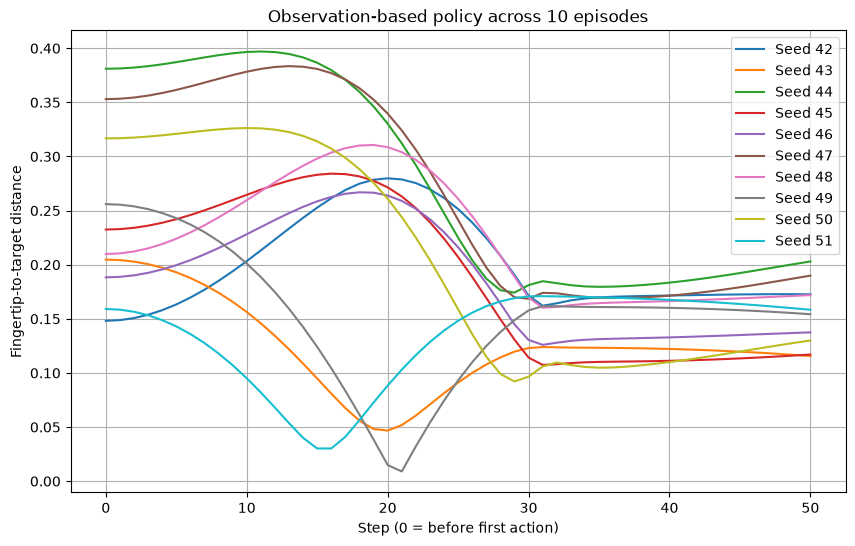

In [33]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

def policy(observation):
    x_offset = observation[8]
    
    if x_offset < 0:
        return np.array([0.05, -0.10], dtype=np.float32)
    else:
        return np.array([-0.05, -0.10], dtype=np.float32)
    
env = gym.make("Reacher-v5", render_mode="human")
success_threshold = 0.05

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward | Success")
print("-" * 85)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action = policy(observation)
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward
    closest_distance = min(distances)
    success = closest_distance <= success_threshold 
    print(
        f"{seed:4d} | {distances[0]:14.6f} | {closest_distance:16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
    )
    plt.plot(range(len(distances)), distances, label=f"Seed {seed}")
        
env.close()

plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Observation-based policy across 10 episodes")
plt.grid(True)
plt.legend()
plt.show()


# Training with PPO(Proximal Policy Optimization)

In [2]:
from pathlib import Path
import gymnasium as gym
from stable_baselines3 import PPO

train_env = gym.make("Reacher-v5")
model = PPO("MlpPolicy", train_env, verbose=2, seed=42)
model.learn(total_timesteps=10_000)

model_path = Path("ppo_reacher_first_run")
model.save(str(model_path))
train_env.close()

print("Saved model as:", model_path.with_suffix(".zip").resolve())

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 50       |
|    ep_rew_mean     | -61.1    |
| time/              |          |
|    fps             | 427      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 50           |
|    ep_rew_mean          | -60.5        |
| time/                   |              |
|    fps                  | 298          |
|    iterations           | 2            |
|    time_elapsed         | 13           |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0034743338 |
|    clip_fraction        | 0.016        |
|    clip_range           | 0.2          |
|    en

In [3]:
print(model._n_updates)

50


In [5]:
import numpy as np

test_env = gym.make("Reacher-v5")
success_threshold = 0.05

print("Seed | Closest distance | Final distance | Total reward | Success")
print("-" * 70)

for seed in range(42, 52):
    observation, info = test_env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action, _ = model.predict(observation, deterministic=True)
        observation, reward, terminated, truncated, info = test_env.step(action)

        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward

    closest_distance = min(distances)
    success = closest_distance <= success_threshold

    print(
        f"{seed:4d} | {closest_distance:16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
    )

test_env.close()

Seed | Closest distance | Final distance | Total reward | Success
----------------------------------------------------------------------
  42 |         0.136941 |       0.145368 |    -9.273828 | False
  43 |         0.019839 |       0.106533 |    -6.182751 | True
  44 |         0.198650 |       0.225501 |   -17.219145 | False
  45 |         0.103287 |       0.125139 |   -10.706110 | False
  46 |         0.116177 |       0.117895 |   -11.084041 | False
  47 |         0.178781 |       0.234418 |   -15.196471 | False
  48 |         0.146393 |       0.158131 |   -10.991600 | False
  49 |         0.120912 |       0.146637 |    -9.207848 | False
  50 |         0.116604 |       0.186783 |   -12.900026 | False
  51 |         0.025155 |       0.154559 |    -4.567413 | True


In [6]:
from datetime import datetime
from pathlib import Path

import gymnasium as gym
from stable_baselines3 import PPO

train_env = gym.make("Reacher-v5")
model = PPO("MlpPolicy", train_env, verbose=2, seed=42)
model.learn(total_timesteps=50_000)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = Path(f"ppo_reacher_first_run_{timestamp}")

model.save(str(model_path))
train_env.close()

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 50       |
|    ep_rew_mean     | -61.1    |
| time/              |          |
|    fps             | 1496     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 50           |
|    ep_rew_mean          | -60.5        |
| time/                   |              |
|    fps                  | 1075         |
|    iterations           | 2            |
|    time_elapsed         | 3            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0034743338 |
|    clip_fraction        | 0.016        |
|    clip_range           | 0.2          |
|    en

# Training with Callback for 5000 steps in 50,000 timesteps

In [7]:
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import EvalCallback

train_env = gym.make("Reacher-v5")
eval_env = gym.make("Reacher-v5")  # Separate environment for checkpoint selection

eval_callback = EvalCallback(
    eval_env,
    best_model_save_path="./ppo_reacher_checkpoints",
    eval_freq=5_000,
    n_eval_episodes=10,
    deterministic=True,
)

model = PPO("MlpPolicy", train_env, verbose=1, seed=42)
model.learn(total_timesteps=50_000, callback=eval_callback)

train_env.close()
eval_env.close()

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 50       |
|    ep_rew_mean     | -61.1    |
| time/              |          |
|    fps             | 1256     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 50           |
|    ep_rew_mean          | -60.5        |
| time/                   |              |
|    fps                  | 987          |
|    iterations           | 2            |
|    time_elapsed         | 4            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0034743338 |
|    clip_fraction        | 0.016        |
|    clip_range           | 0.2          |
|    en

c:\Users\rozak\Downloads\reacher-first-experiment\.venv\Lib\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Eval num_timesteps=5000, episode_reward=-9.57 +/- 3.89
Episode length: 50.00 +/- 0.00
------------------------------------------
| eval/                   |              |
|    mean_ep_length       | 50           |
|    mean_reward          | -9.57        |
| time/                   |              |
|    total_timesteps      | 5000         |
| train/                  |              |
|    approx_kl            | 0.0063042985 |
|    clip_fraction        | 0.0456       |
|    clip_range           | 0.2          |
|    entropy_loss         | -2.78        |
|    explained_variance   | 0.346        |
|    learning_rate        | 0.0003       |
|    loss                 | 19.4         |
|    n_updates            | 20           |
|    policy_gradient_loss | -0.00746     |
|    std                  | 0.959        |
|    value_loss           | 104          |
------------------------------------------
New best mean reward!
---------------------------------
| rollout/           |          |
|    ep

Evaluating: C:\Users\rozak\Downloads\reacher-first-experiment\ppo_reacher_checkpoints\best_model.zip
Seed | Closest distance | Final distance | Total reward | Success
----------------------------------------------------------------------
  42 |         0.130230 |       0.144016 |    -7.992446 | False
  43 |         0.100942 |       0.105929 |    -7.741380 | False
  44 |         0.203840 |       0.217512 |   -16.691490 | False
  45 |         0.105067 |       0.119694 |    -9.982390 | False
  46 |         0.111088 |       0.118162 |    -8.963556 | False
  47 |         0.187292 |       0.211350 |   -15.070437 | False
  48 |         0.147119 |       0.156883 |   -10.205513 | False
  49 |         0.151385 |       0.151385 |   -10.323670 | False
  50 |         0.125672 |       0.148676 |   -12.559329 | False
  51 |         0.093127 |       0.142781 |    -6.612066 | False
Successes: 0/10


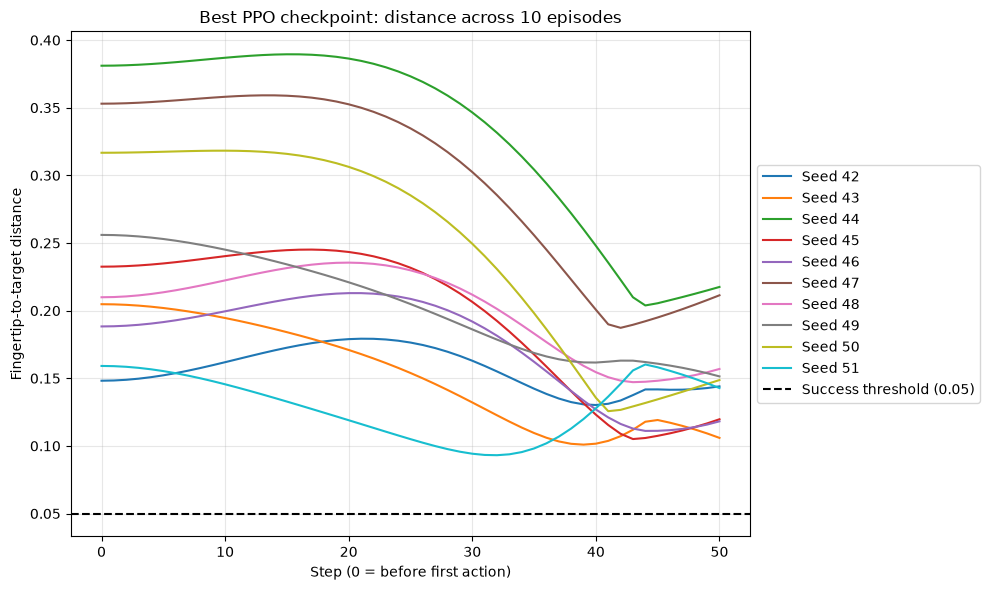

In [8]:
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from stable_baselines3 import PPO

best_path = Path("ppo_reacher_checkpoints") / "best_model.zip"
if not best_path.exists():
    raise FileNotFoundError(f"Model not found: {best_path.resolve()}")

best_model = PPO.load(str(best_path))
test_env = gym.make("Reacher-v5")

success_threshold = 0.05
success_count = 0
episode_distances = {}

print("Evaluating:", best_path.resolve())
print("Seed | Closest distance | Final distance | Total reward | Success")
print("-" * 70)

try:
    for seed in range(42, 52):
        observation, info = test_env.reset(seed=seed)
        distances = [np.linalg.norm(observation[8:10])]  # Step 0
        total_reward = 0.0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            action, _ = best_model.predict(observation, deterministic=True)
            observation, reward, terminated, truncated, info = test_env.step(action)

            distances.append(np.linalg.norm(observation[8:10]))
            total_reward += reward

        episode_distances[seed] = distances
        closest_distance = min(distances)
        success = closest_distance <= success_threshold
        success_count += int(success)

        print(
            f"{seed:4d} | {closest_distance:16.6f} "
            f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
        )
finally:
    test_env.close()

print(f"Successes: {success_count}/10")

fig, ax = plt.subplots(figsize=(10, 6))
for seed, distances in episode_distances.items():
    ax.plot(range(len(distances)), distances, label=f"Seed {seed}", linewidth=1.5)

ax.axhline(
    success_threshold,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Success threshold (0.05)",
)
ax.set(
    xlabel="Step (0 = before first action)",
    ylabel="Fingertip-to-target distance",
    title="Best PPO checkpoint: distance across 10 episodes",
)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()

In [9]:
model.save("ppo_reacher_final_50k")

Evaluating: C:\Users\rozak\Downloads\reacher-first-experiment\ppo_reacher_final_50k.zip
Seed | Closest distance | Final distance | Total reward | Success
----------------------------------------------------------------------
  42 |         0.023784 |       0.137107 |   -57.686005 | True
  43 |         0.053437 |       0.121021 |   -55.842600 | False
  44 |         0.044222 |       0.208880 |   -60.682184 | True
  45 |         0.046821 |       0.104872 |   -56.584557 | True
  46 |         0.034551 |       0.106176 |   -56.762329 | True
  47 |         0.007657 |       0.199266 |   -60.300776 | True
  48 |         0.046304 |       0.141467 |   -58.112797 | True
  49 |         0.054430 |       0.162238 |   -57.458269 | False
  50 |         0.058216 |       0.136880 |   -57.383019 | False
  51 |         0.016414 |       0.162512 |   -57.111784 | True
Successes: 7/10


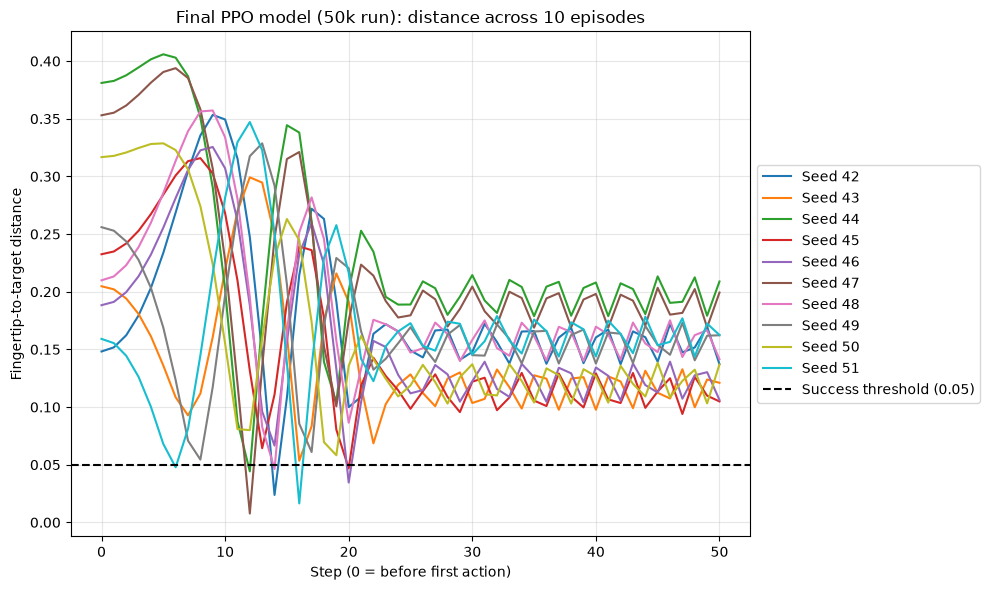

In [12]:
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from stable_baselines3 import PPO

final_path = Path("ppo_reacher_final_50k.zip")
if not final_path.exists():
    raise FileNotFoundError(f"Final model not found: {final_path.resolve()}")

final_model = PPO.load(str(final_path))
test_env = gym.make("Reacher-v5")

success_threshold = 0.05
success_count = 0
episode_distances = {}

print("Evaluating:", final_path.resolve())
print("Seed | Closest distance | Final distance | Total reward | Success")
print("-" * 70)

try:
    for seed in range(42, 52):
        observation, info = test_env.reset(seed=seed)
        distances = [np.linalg.norm(observation[8:10])]  # Step 0
        total_reward = 0.0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            action, _ = final_model.predict(observation, deterministic=True)
            observation, reward, terminated, truncated, info = test_env.step(action)

            distances.append(np.linalg.norm(observation[8:10]))
            total_reward += reward

        episode_distances[seed] = distances
        closest_distance = min(distances)
        success = closest_distance <= success_threshold
        success_count += int(success)

        print(
            f"{seed:4d} | {closest_distance:16.6f} "
            f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
        )
finally:
    test_env.close()

print(f"Successes: {success_count}/10")

fig, ax = plt.subplots(figsize=(10, 6))
for seed, distances in episode_distances.items():
    ax.plot(range(len(distances)), distances, label=f"Seed {seed}", linewidth=1.5)

ax.axhline(
    success_threshold,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Success threshold (0.05)",
)
ax.set(
    xlabel="Step (0 = before first action)",
    ylabel="Fingertip-to-target distance",
    title="Final PPO model (50k run): distance across 10 episodes",
)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()

# Add separate the Two Part of Reacher Reward



In [14]:
from pathlib import Path

import gymnasium as gym
from stable_baselines3 import PPO

model_path = Path("ppo_reacher_final_50k.zip")
if not model_path.exists():
    raise FileNotFoundError(f"Model not found: {model_path.resolve()}")

final_model = PPO.load(str(model_path))
env = gym.make("Reacher-v5")

observation, info = env.reset(seed=47)
total_reward = 0.0
total_distance_score = 0.0
total_action_score = 0.0
terminated = False
truncated = False
steps = 0

try:
    while not (terminated or truncated):
        action, _ = final_model.predict(observation, deterministic=True)
        observation, reward, terminated, truncated, info = env.step(action)

        total_reward += reward
        total_distance_score += info["reward_dist"]
        total_action_score += info["reward_ctrl"]
        steps += 1
finally:
    env.close()

print("Steps:", steps)
print(f"Distance score total: {total_distance_score:.6f}")
print(f"Action score total:   {total_action_score:.6f}")
print(f"Sum of both:          {total_distance_score + total_action_score:.6f}")
print(f"Total reward:         {total_reward:.6f}")

Steps: 50
Distance score total: -11.041945
Action score total:   -49.258839
Sum of both:          -60.300784
Total reward:         -60.300776


# Evaluate the reacher with different seeds that never trained


Reward-selected checkpoint
Seed | Closest | Final | Steps within 0.05 | Distance reward | Action reward | Total reward
 100 | 0.029975 | 0.170138 |               11 |       -4.458281 |     -0.170643 |    -4.628924
 101 | 0.186407 | 0.204907 |                0 |      -14.513303 |     -0.176361 |   -14.689664
 102 | 0.004620 | 0.048997 |               10 |       -4.586354 |     -0.172497 |    -4.758851
 103 | 0.114562 | 0.128334 |                0 |      -12.310980 |     -0.173146 |   -12.484126
 104 | 0.109625 | 0.135135 |                0 |      -10.939444 |     -0.178008 |   -11.117452
 105 | 0.132871 | 0.132871 |                0 |      -10.886700 |     -0.175727 |   -11.062427
 106 | 0.152231 | 0.152231 |                0 |      -12.275140 |     -0.179074 |   -12.454214
 107 | 0.168811 | 0.168811 |                0 |      -11.158676 |     -0.174266 |   -11.332941
 108 | 0.212046 | 0.212046 |                0 |      -14.969173 |     -0.178876 |   -15.148049
 109 | 0.117635 | 0.11763

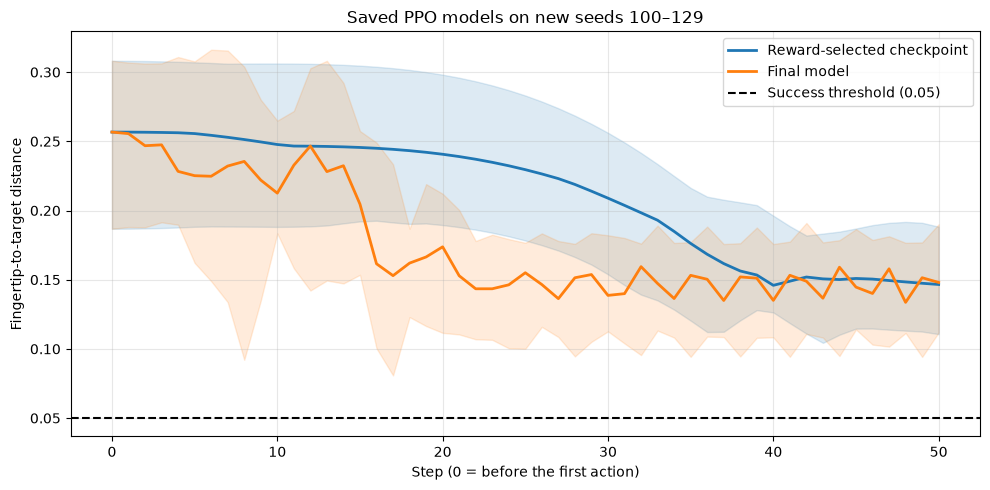

In [15]:
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from stable_baselines3 import PPO

models = {
    "Reward-selected checkpoint": Path("ppo_reacher_checkpoints/best_model.zip"),
    "Final model": Path("ppo_reacher_final_50k.zip"),
}
new_seeds = range(100, 130)
threshold = 0.05
trajectories = {}

for name, path in models.items():
    if not path.exists():
        raise FileNotFoundError(path.resolve())

    model = PPO.load(str(path))
    env = gym.make("Reacher-v5", render_mode="human")
    successes = 0
    trajectories[name] = []

    print(f"\n{name}")
    print(
        "Seed | Closest | Final | Steps within 0.05 | "
        "Distance reward | Action reward | Total reward"
    )

    try:
        for seed in new_seeds:
            observation, _ = env.reset(seed=seed)
            distances = [float(np.linalg.norm(observation[8:10]))]
            distance_reward = 0.0
            action_reward = 0.0
            total_reward = 0.0
            terminated = truncated = False

            while not (terminated or truncated):
                action, _ = model.predict(observation, deterministic=True)
                observation, reward, terminated, truncated, info = env.step(action)

                distances.append(float(np.linalg.norm(observation[8:10])))
                distance_reward += info["reward_dist"]
                action_reward += info["reward_ctrl"]
                total_reward += reward

            trajectories[name].append(distances)
            closest = min(distances)
            successes += int(closest <= threshold)
            steps_within = sum(d <= threshold for d in distances[1:])

            print(
                f"{seed:4d} | {closest:.6f} | {distances[-1]:.6f} "
                f"| {steps_within:16d} | {distance_reward:15.6f} "
                f"| {action_reward:13.6f} | {total_reward:12.6f}"
            )
    finally:
        env.close()

    print(f"Provisional successes: {successes}/{len(new_seeds)}")

# Plot the median distance at each step; shading shows the middle 50% of episodes.
fig, ax = plt.subplots(figsize=(10, 5))

for name, episode_distances in trajectories.items():
    distances_by_step = np.asarray(episode_distances)
    steps = np.arange(distances_by_step.shape[1])

    median = np.median(distances_by_step, axis=0)
    lower = np.percentile(distances_by_step, 25, axis=0)
    upper = np.percentile(distances_by_step, 75, axis=0)

    line, = ax.plot(steps, median, label=name, linewidth=2)
    ax.fill_between(steps, lower, upper, color=line.get_color(), alpha=0.15)

ax.axhline(
    threshold, color="black", linestyle="--",
    linewidth=1.5, label="Success threshold (0.05)"
)
ax.set(
    title="Saved PPO models on new seeds 100–129",
    xlabel="Step (0 = before the first action)",
    ylabel="Fingertip-to-target distance",
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()